# Making events_long df 

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

In [2]:
file ='/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/final_datasets/lowCF_filtered_merged_with_incdec_MCD12Q1mask_2024.parquet'
df= pd.read_parquet(file, engine='pyarrow')
 

In [3]:
print('Total rows in your 2026 dataset:', len(df))

Total rows in your 2026 dataset: 38482560


In [4]:
df.head(7)

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,tz_name,datetime_utc,datetime_local,time_diff_hours,pulse_start,sm_surface,surface_temp,soil_temp_layer1,WFPS_c,dominant_texture,state_name,timezone,pre_slope,sm_class
0,36.05,-91.05,NaN,2024-03-01 00:00:00,NaN,NaN,NaN,NaT,2024-02-29 18:00:00,NaN,False,0.188113,203.515932,204.294951,0.422821,sandy loam,Arkansas,America/Chicago,NaN,NaN
1,36.05,-91.05,NaN,2024-03-01 01:00:00,NaN,NaN,NaN,NaT,2024-02-29 19:00:00,NaN,False,0.179144,202.797299,204.143615,0.402660,sandy loam,Arkansas,America/Chicago,NaN,NaN
2,36.05,-91.05,0.0,2024-03-01 02:00:00,NaN,NaN,NaN,NaT,2024-02-29 20:00:00,NaN,False,0.175506,202.309476,203.927366,0.394484,sandy loam,Arkansas,America/Chicago,NaN,NaN
3,36.05,-91.05,0.0,2024-03-01 03:00:00,NaN,NaN,NaN,NaT,2024-02-29 21:00:00,NaN,False,0.176829,202.036375,203.650729,0.397458,sandy loam,Arkansas,America/Chicago,NaN,NaN
4,36.05,-91.05,NaN,2024-03-01 04:00:00,NaN,NaN,NaN,NaT,2024-02-29 22:00:00,NaN,False,0.178152,201.763273,203.374092,0.400431,sandy loam,Arkansas,America/Chicago,NaN,NaN
5,36.05,-91.05,NaN,2024-03-01 05:00:00,NaN,NaN,NaN,NaT,2024-02-29 23:00:00,NaN,False,0.181154,201.555054,203.151193,0.407178,sandy loam,Arkansas,America/Chicago,NaN,NaN
6,36.05,-91.05,NaN,2024-03-01 06:00:00,NaN,NaN,NaN,NaT,2024-03-01 00:00:00,NaN,False,0.185717,201.407197,202.978285,0.417436,sandy loam,Arkansas,America/Chicago,NaN,NaN


In [5]:
df.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'tz_name', 'datetime_utc', 'datetime_local',
       'time_diff_hours', 'pulse_start', 'sm_surface', 'surface_temp',
       'soil_temp_layer1', 'WFPS_c', 'dominant_texture', 'state_name',
       'timezone', 'pre_slope', 'sm_class'],
      dtype='str')

In [6]:
df = df.copy()
df["datetime"] = pd.to_datetime(df["datetime"])
df["datetime_local"] = pd.to_datetime(df["datetime_local"])
df = df.sort_values(["grid_lat", "grid_lon", "datetime"]).reset_index(drop=True)

In [7]:
keep_cols = ["dominant_texture", "state_name", "datetime_local", "pre_slope", "sm_class"]

#variables to average within each lag day
avg_cols = [
    "no2_mean",
    'sm_surface',
    "WFPS_c",
    "h_precip_mm",
    "surface_temp",
    "soil_temp_layer1"]


In [8]:
# get pulse rows (ALL hours) and give ID
pulse_df = df[df["pulse_start"] == True].copy().reset_index(drop=True)

# to go back to 10am+ only:
# pulse_df = pulse_df[pd.to_datetime(pulse_df["datetime_local"]).dt.hour >= 10].reset_index(drop=True)

pulse_df["event_id"] = np.arange(len(pulse_df))
records = []

In [9]:
from tqdm import tqdm

In [10]:
grouped_cells = dict(tuple(df.groupby(["grid_lat", "grid_lon"])))

# build windows
for _, pulse in tqdm(pulse_df.iterrows(), total=len(pulse_df), desc="building event windows"):
    lat = pulse["grid_lat"]
    lon = pulse["grid_lon"]
    t0 = pulse["datetime"]

    #all data at this grid cell
    sub = grouped_cells.get((lat, lon))
    if sub is None:
        continue

    #keep only +/- 7 day window
    sub = sub[
        (sub["datetime"] >= t0 - pd.Timedelta(days=7)) &
        (sub["datetime"] <= t0 + pd.Timedelta(days=7))].copy()

    if sub.empty:
        continue
    #lag in integer days relative to pulse time
    sub["lag_days"] = ((sub["datetime"] - t0) / pd.Timedelta(days=1)).apply(np.floor).astype(int)
    sub = sub[(sub["lag_days"] >= -14) & (sub["lag_days"] <= 14)].copy()
    #daily averages 
    grouped = (sub.groupby("lag_days", as_index=False)[avg_cols].mean())

    #add pulse data back onto every lag row
    grouped["event_id"] = pulse["event_id"]
    grouped["grid_lat"] = lat
    grouped["grid_lon"] = lon
    grouped["datetime_event"] = t0
    grouped["pulse_date"] = t0.normalize()

    for col in keep_cols:
        grouped[col] = pulse[col]

    records.append(grouped)


building event windows: 100%|██████████| 16583/16583 [02:03<00:00, 134.23it/s]


In [11]:
#combine!!
events_long = pd.concat(records, ignore_index=True)
front_cols = ["event_id", "grid_lat", "grid_lon", "datetime_event", "pulse_date", "lag_days",
              "no2_mean","WFPS_c", "sm_surface", "h_precip_mm", "surface_temp", "soil_temp_layer1"]

events_long = events_long[front_cols + keep_cols]
events_long = events_long.sort_values(["event_id", "lag_days"]).reset_index(drop=True)
events_long.head()

,event_id,grid_lat,grid_lon,datetime_event,pulse_date,lag_days,no2_mean,WFPS_c,sm_surface,h_precip_mm,surface_temp,soil_temp_layer1,dominant_texture,state_name,datetime_local,pre_slope,sm_class
0,0,36.05,-91.05,2024-05-20 12:00:00,2024-05-20,-7,NaN,0.381942,0.169926,0.000000,213.085230,212.756644,sandy loam,Arkansas,2024-05-20 07:00:00,0.001014,increasing
1,0,36.05,-91.05,2024-05-20 12:00:00,2024-05-20,-6,1.478290e+15,0.427095,0.190015,0.000000,212.857011,212.937080,sandy loam,Arkansas,2024-05-20 07:00:00,0.001014,increasing
2,0,36.05,-91.05,2024-05-20 12:00:00,2024-05-20,-5,1.546435e+15,0.315410,0.140326,0.000000,214.411305,213.634041,sandy loam,Arkansas,2024-05-20 07:00:00,0.001014,increasing
3,0,36.05,-91.05,2024-05-20 12:00:00,2024-05-20,-4,3.086789e+15,0.359275,0.159841,0.391562,214.666908,214.106583,sandy loam,Arkansas,2024-05-20 07:00:00,0.001014,increasing
4,0,36.05,-91.05,2024-05-20 12:00:00,2024-05-20,-3,1.138022e+15,0.501964,0.223324,1.999062,213.449183,213.358855,sandy loam,Arkansas,2024-05-20 07:00:00,0.001014,increasing


In [12]:
events_long.columns

Index(['event_id', 'grid_lat', 'grid_lon', 'datetime_event', 'pulse_date',
       'lag_days', 'no2_mean', 'WFPS_c', 'sm_surface', 'h_precip_mm',
       'surface_temp', 'soil_temp_layer1', 'dominant_texture', 'state_name',
       'datetime_local', 'pre_slope', 'sm_class'],
      dtype='str')

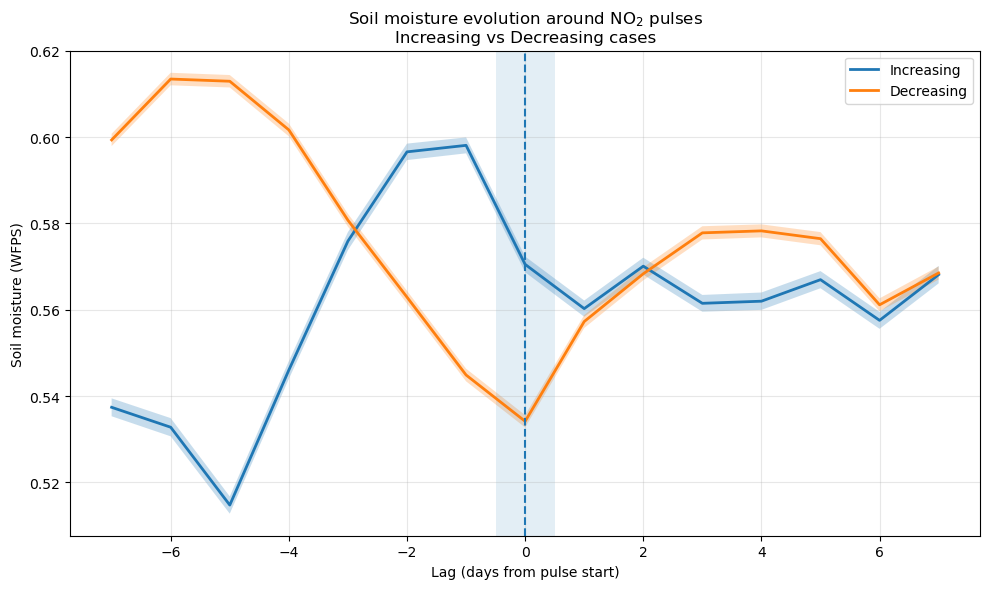

In [13]:
plot_df = events_long.copy()

#keep only two classes 
plot_df = plot_df[plot_df["sm_class"].isin(["increasing", "decreasing"])].copy()
plot_df = plot_df.dropna(subset=["lag_days", "WFPS_c", "sm_class"])

summary = (plot_df.groupby(["sm_class", "lag_days"])["WFPS_c"].agg(["mean", "std", "count"]).reset_index())
summary["sem"] =summary["std"] / np.sqrt(summary["count"])

inc =summary[summary["sm_class"] == "increasing"].copy()
dec =summary[summary["sm_class"] == "decreasing"].copy()

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(inc["lag_days"],inc["mean"],label="Increasing",linewidth=2)
ax.fill_between(inc["lag_days"],inc["mean"] - inc["sem"],inc["mean"] + inc["sem"],alpha=0.25)

ax.plot(dec["lag_days"],dec["mean"],label="Decreasing",linewidth=2)
ax.fill_between(dec["lag_days"],dec["mean"] - dec["sem"],dec["mean"] + dec["sem"], alpha=0.25)


ax.axvline(0, linestyle="--", linewidth=1.5)
ax.axvspan(-0.5, 0.5, alpha=0.12)

ax.set_xlabel("Lag (days from pulse start)")
ax.set_ylabel("Soil moisture (WFPS)")
ax.set_title("Soil moisture evolution around NO$_2$ pulses\nIncreasing vs Decreasing cases")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
print(events_long.groupby('sm_class')['event_id'].nunique())

sm_class
decreasing    10556
increasing     6025
no data           2
Name: event_id, dtype: int64


In [15]:
pulse_df['local_hour'] = pd.to_datetime(pulse_df['datetime_local']).dt.hour
print(pulse_df['local_hour'].describe())

count    16583.000000
mean         8.905084
std          2.353904
min          6.000000
25%          7.000000
50%          8.000000
75%         10.000000
max         18.000000
Name: local_hour, dtype: float64


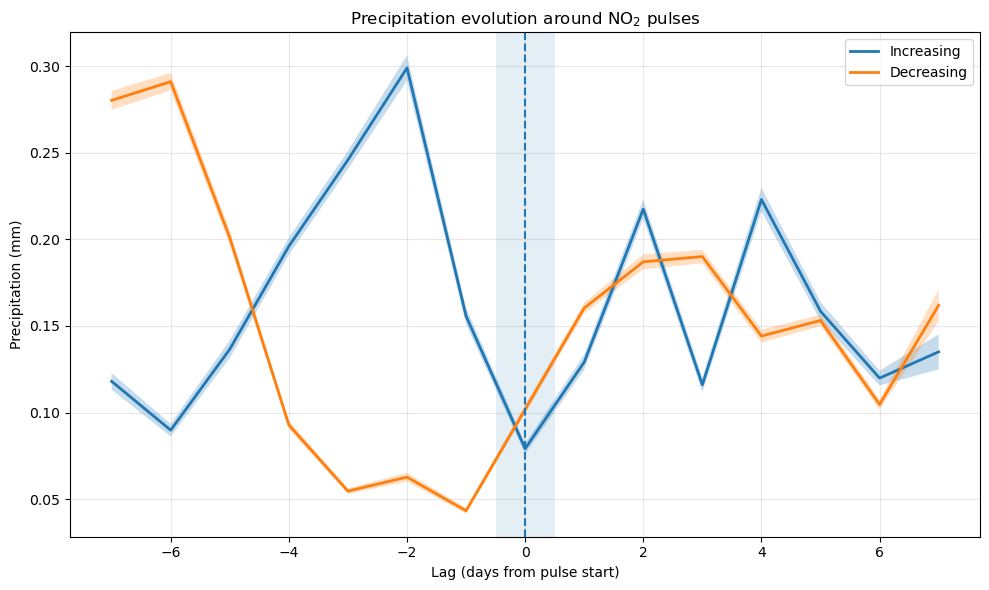

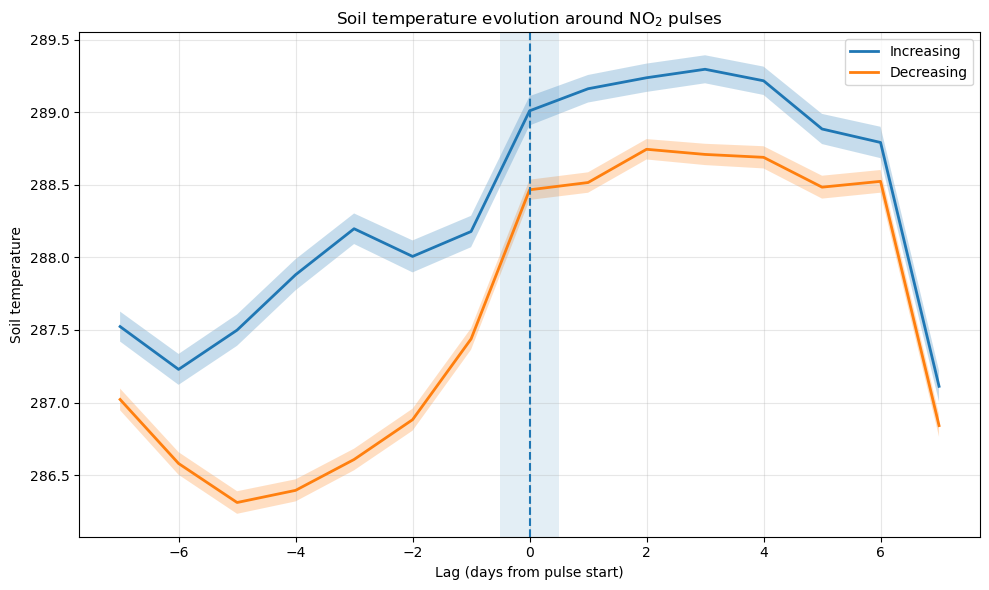

In [16]:
plot_df = events_long.copy()

plot_df =plot_df[plot_df["sm_class"].isin(["increasing", "decreasing"])].copy()
plot_df =plot_df.dropna(subset=["event_id", "lag_days", "sm_class"])

event_lag = (plot_df.groupby(["sm_class", "event_id", "lag_days"], as_index=False)[
             ["h_precip_mm", "soil_temp_layer1"]].mean())
 
summary =(event_lag.groupby(["sm_class", "lag_days"])[["h_precip_mm", "soil_temp_layer1"]]
          .agg(["mean", "std", "count"])
          .reset_index())

summary.columns = ["sm_class", "lag_days",
                   "precip_mean", "precip_std", "precip_count",
                   "soiltemp_mean", "soiltemp_std", "soiltemp_count"]

summary["precip_sem"] =summary["precip_std"] /np.sqrt(summary["precip_count"])
summary["soiltemp_sem"]= summary["soiltemp_std"] /np.sqrt(summary["soiltemp_count"])

inc =summary[summary["sm_class"] =="increasing"].copy()
dec =summary[summary["sm_class"] =="decreasing"].copy()

#plot precip
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(inc["lag_days"], inc["precip_mean"], label="Increasing", linewidth=2)
ax.fill_between(inc["lag_days"],
                inc["precip_mean"] - inc["precip_sem"],
                inc["precip_mean"] + inc["precip_sem"],
                alpha=0.25)

ax.plot(dec["lag_days"], dec["precip_mean"], label="Decreasing", linewidth=2)
ax.fill_between(dec["lag_days"],
                dec["precip_mean"] - dec["precip_sem"],
                dec["precip_mean"] + dec["precip_sem"],
                alpha=0.25)

ax.axvline(0, linestyle="--", linewidth=1.5)
ax.axvspan(-0.5, 0.5, alpha=0.12)

ax.set_xlabel("Lag (days from pulse start)")
ax.set_ylabel("Precipitation (mm)")
ax.set_title("Precipitation evolution around NO$_2$ pulses")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(inc["lag_days"], inc["soiltemp_mean"], label="Increasing", linewidth=2)
ax.fill_between(inc["lag_days"],
                inc["soiltemp_mean"] - inc["soiltemp_sem"],
                inc["soiltemp_mean"] + inc["soiltemp_sem"],
                alpha=0.25)

ax.plot(dec["lag_days"], dec["soiltemp_mean"], label="Decreasing", linewidth=2)
ax.fill_between(dec["lag_days"],
                dec["soiltemp_mean"] - dec["soiltemp_sem"],
                dec["soiltemp_mean"] + dec["soiltemp_sem"],
                alpha=0.25)

ax.axvline(0, linestyle="--", linewidth=1.5)
ax.axvspan(-0.5, 0.5, alpha=0.12)

ax.set_xlabel("Lag (days from pulse start)")
ax.set_ylabel("Soil temperature")
ax.set_title("Soil temperature evolution around NO$_2$ pulses")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [17]:
pre_df = event_lag[event_lag["lag_days"] < 0].copy()
pre_df["h_precip_mm"] =pre_df["h_precip_mm"].fillna(0)


event_metrics = (
    pre_df.groupby(["sm_class", "event_id"])
    .apply(lambda g: pd.Series({
        "total_precip_pre": g["h_precip_mm"].sum(),
        "max_precip": g["h_precip_mm"].max(),
        "lag_of_max_precip": g.loc[g["h_precip_mm"].idxmax(), "lag_days"]}))
    .reset_index())

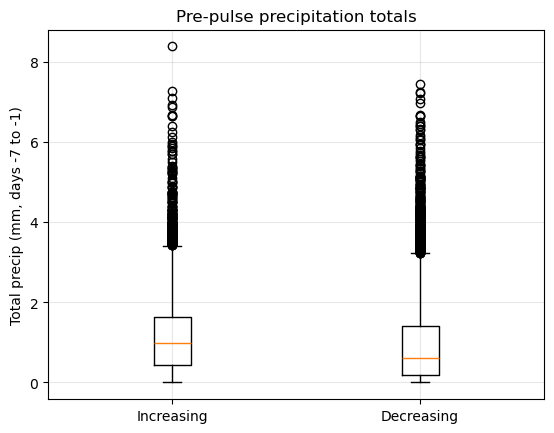

In [18]:
inc = event_metrics[event_metrics["sm_class"] == "increasing"]["total_precip_pre"]
dec = event_metrics[event_metrics["sm_class"] == "decreasing"]["total_precip_pre"]

plt.boxplot([inc, dec])
plt.xticks([1, 2], ["Increasing", "Decreasing"])
plt.ylabel("Total precip (mm, days -7 to -1)")
plt.title("Pre-pulse precipitation totals")
plt.grid(True, alpha=0.3)
plt.show()

In [19]:
events_long

,event_id,grid_lat,grid_lon,datetime_event,pulse_date,lag_days,no2_mean,WFPS_c,sm_surface,h_precip_mm,surface_temp,soil_temp_layer1,dominant_texture,state_name,datetime_local,pre_slope,sm_class
0,0,36.05,-91.05,2024-05-20 12:00:00,2024-05-20,-7,NaN,0.381942,0.169926,0.000000,213.085230,212.756644,sandy loam,Arkansas,2024-05-20 07:00:00,0.001014,increasing
1,0,36.05,-91.05,2024-05-20 12:00:00,2024-05-20,-6,1.478290e+15,0.427095,0.190015,0.000000,212.857011,212.937080,sandy loam,Arkansas,2024-05-20 07:00:00,0.001014,increasing
2,0,36.05,-91.05,2024-05-20 12:00:00,2024-05-20,-5,1.546435e+15,0.315410,0.140326,0.000000,214.411305,213.634041,sandy loam,Arkansas,2024-05-20 07:00:00,0.001014,increasing
3,0,36.05,-91.05,2024-05-20 12:00:00,2024-05-20,-4,3.086789e+15,0.359275,0.159841,0.391562,214.666908,214.106583,sandy loam,Arkansas,2024-05-20 07:00:00,0.001014,increasing
4,0,36.05,-91.05,2024-05-20 12:00:00,2024-05-20,-3,1.138022e+15,0.501964,0.223324,1.999062,213.449183,213.358855,sandy loam,Arkansas,2024-05-20 07:00:00,0.001014,increasing
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
247210,16582,48.95,-96.95,2024-04-09 17:00:00,2024-04-09,3,1.754116e+15,0.408585,0.190719,0.019250,283.055019,280.379369,clay,Minnesota,2024-04-09 12:00:00,-0.000321,decreasing
247211,16582,48.95,-96.95,2024-04-09 17:00:00,2024-04-09,4,1.781318e+15,0.410456,0.191597,0.257222,284.676463,282.130697,clay,Minnesota,2024-04-09 12:00:00,-0.000321,decreasing
247212,16582,48.95,-96.95,2024-04-09 17:00:00,2024-04-09,5,1.832872e+15,0.382916,0.178755,0.000000,283.917086,282.194806,clay,Minnesota,2024-04-09 12:00:00,-0.000321,decreasing
247213,16582,48.95,-96.95,2024-04-09 17:00:00,2024-04-09,6,NaN,0.475152,0.221444,0.363684,283.211206,281.577807,clay,Minnesota,2024-04-09 12:00:00,-0.000321,decreasing


In [20]:
events_long.columns

Index(['event_id', 'grid_lat', 'grid_lon', 'datetime_event', 'pulse_date',
       'lag_days', 'no2_mean', 'WFPS_c', 'sm_surface', 'h_precip_mm',
       'surface_temp', 'soil_temp_layer1', 'dominant_texture', 'state_name',
       'datetime_local', 'pre_slope', 'sm_class'],
      dtype='str')

In [21]:
event_lag = (
    events_long
    .groupby(["sm_class", "event_id", "lag_days"], as_index=False)
    .agg({
        "h_precip_mm": "mean",
        "soil_temp_layer1": "mean",
        "sm_surface": "mean",
        "dominant_texture": "first",  
        "state_name": "first"}))

In [22]:
texture_map = {
    "sand": "coarse",
    "loamy sand": "coarse",
    "sandy loam": "moderately_coarse",
    
    "loam": "medium",
    "silt loam": "medium",
    "silt": "medium",
    
    "clay loam": "fine",
    "silty clay loam": "fine",
    "sandy clay loam": "fine",
    
    "clay": "very_fine",
    "silty clay": "very_fine",
    "sandy clay": "very_fine"}

event_lag["soil_group"] = event_lag["dominant_texture"].map(texture_map)

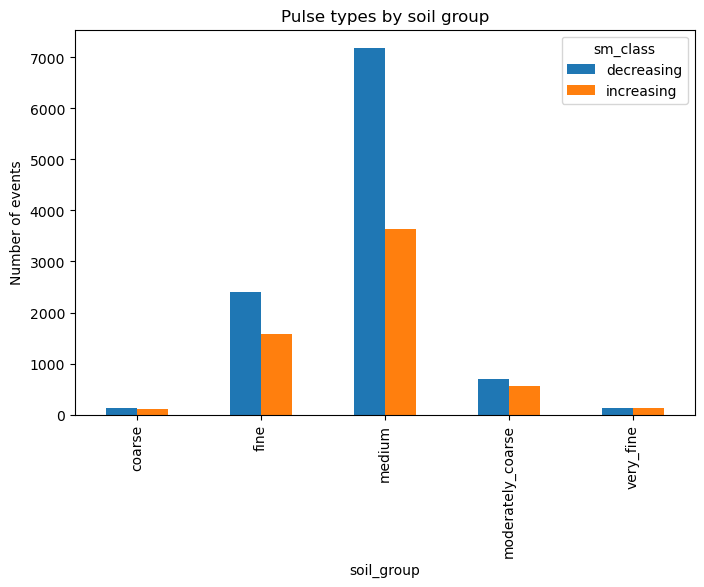

In [23]:
event_lag_filtered = event_lag[event_lag['sm_class'].isin(['increasing', 'decreasing'])]

counts = (event_lag_filtered.groupby(["soil_group", "sm_class"])["event_id"].nunique().unstack())

counts.plot(kind="bar", figsize=(8,5))
plt.ylabel("Number of events")
plt.title("Pulse types by soil group")
plt.show()

In [27]:
pulse_df = df[df["pulse_start"] == True].copy()

In [28]:
pulse_df = pulse_df.dropna(subset=["no2_mean"])

In [29]:
pulse_df['no2_mean'].describe()

count    1.658300e+04
mean     3.451861e+15
std      1.038560e+15
min      1.245069e+15
25%      2.731172e+15
50%      3.313064e+15
75%      3.971549e+15
max      1.224536e+16
Name: no2_mean, dtype: float64

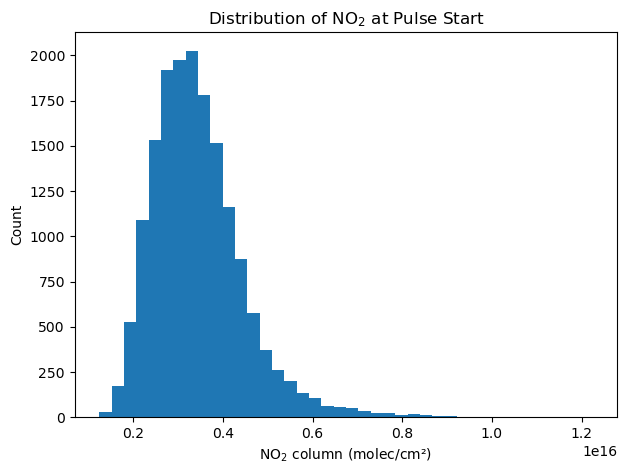

In [30]:
plt.figure(figsize=(7,5))
plt.hist(pulse_df["no2_mean"], bins=40)
plt.xlabel("NO$_2$ column (molec/cm²)")
plt.ylabel("Count")
plt.title("Distribution of NO$_2$ at Pulse Start")
plt.show()

In [32]:
from pathlib import Path
output_file = '/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/final_datasets/lowCF_7day_events_long_MCD12Q1mask_2024.parquet'
Path(output_file).parent.mkdir(parents=True, exist_ok=True)
events_long.to_parquet(output_file, engine='pyarrow')
print('Saved to:', output_file)


Saved to: /global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/final_datasets/lowCF_7day_events_long_MCD12Q1mask_2024.parquet
